In [ ]:
from google.colab import files
up = files.upload()
import pandas as pd
df = pd.read_csv(list(up.keys())[0])
print(df.head()); df.info(); print(df.isnull().sum().sum())

Saving web-page-phishing.csv to web-page-phishing.csv
   url_length  n_dots  n_hypens  n_underline  n_slash  n_questionmark  \
0          37       3         0            0        0               0   
1          77       1         0            0        0               0   
2         126       4         1            2        0               1   
3          18       2         0            0        0               0   
4          55       2         2            0        0               0   

   n_equal  n_at  n_and  n_exclamation  n_space  n_tilde  n_comma  n_plus  \
0        0     0      0              0        0        0        0       0   
1        0     0      0              0        0        0        0       0   
2        3     0      2              0        0        0        0       0   
3        0     0      0              0        0        0        0       0   
4        0     0      0              0        0        0        0       0   

   n_asterisk  n_hastag  n_dollar  n_percent

In [ ]:
from sklearn.model_selection import train_test_split
print(df.columns.tolist())          # check the last name
target = df.columns[-1]             # should print 'phishing'
print("Target:", target)

df = df.drop_duplicates().dropna()
print(df[target].value_counts())

X = df.drop(columns=target); y = df[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

['url_length', 'n_dots', 'n_hypens', 'n_underline', 'n_slash', 'n_questionmark', 'n_equal', 'n_at', 'n_and', 'n_exclamation', 'n_space', 'n_tilde', 'n_comma', 'n_plus', 'n_asterisk', 'n_hastag', 'n_dollar', 'n_percent', 'n_redirection', 'phishing']
Target: phishing
phishing
1    15872
0     6019
Name: count, dtype: int64
(17512, 19) (4379, 19)


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

models = {
 "Random Forest": RandomForestClassifier(random_state=42),
 "Decision Tree": DecisionTreeClassifier(random_state=42),
 "Naive Bayes": GaussianNB(),
 "Logistic Regression": LogisticRegression(max_iter=2000),
}
rows, preds = [], {}
for n, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test); preds[n] = p
    print("\n", n); print(classification_report(y_test, p))
    rows.append([n, accuracy_score(y_test,p),
        precision_score(y_test,p,average='weighted'),
        recall_score(y_test,p,average='weighted'),
        f1_score(y_test,p,average='weighted')])
res = pd.DataFrame(rows, columns=["Model","Accuracy","Precision","Recall","F1"]).round(4)
res.to_csv("results.csv", index=False)
res


 Random Forest
              precision    recall  f1-score   support

           0       0.54      0.50      0.52      1214
           1       0.81      0.83      0.82      3165

    accuracy                           0.74      4379
   macro avg       0.68      0.67      0.67      4379
weighted avg       0.74      0.74      0.74      4379


 Decision Tree
              precision    recall  f1-score   support

           0       0.47      0.53      0.50      1214
           1       0.81      0.77      0.79      3165

    accuracy                           0.70      4379
   macro avg       0.64      0.65      0.64      4379
weighted avg       0.72      0.70      0.71      4379


 Naive Bayes
              precision    recall  f1-score   support

           0       0.32      0.99      0.48      1214
           1       0.97      0.20      0.33      3165

    accuracy                           0.42      4379
   macro avg       0.65      0.59      0.41      4379
weighted avg       0.79     

,Model,Accuracy,Precision,Recall,F1
0,Random Forest,0.7424,0.7376,0.7424,0.7398
1,Decision Tree,0.7034,0.7166,0.7034,0.7089
2,Naive Bayes,0.4179,0.7929,0.4179,0.3741
3,Logistic Regression,0.7737,0.7631,0.7737,0.7661


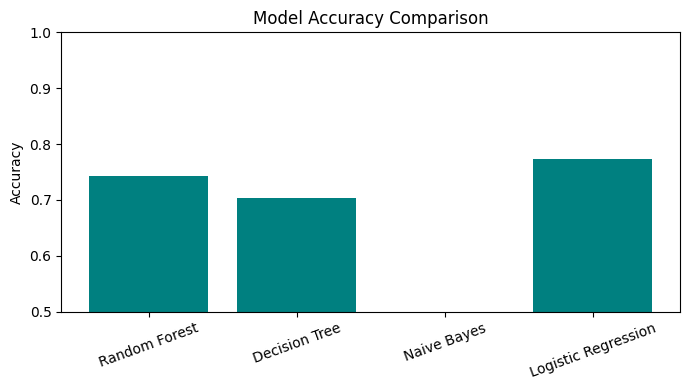

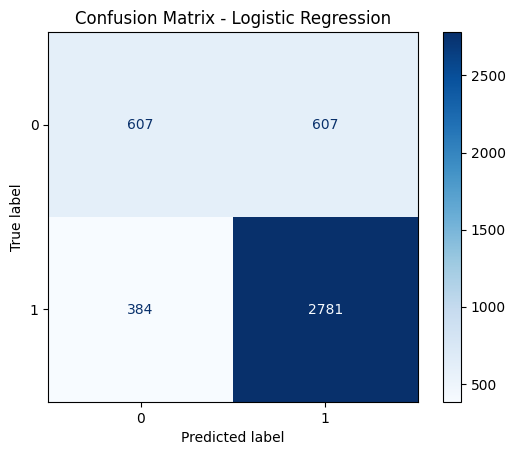

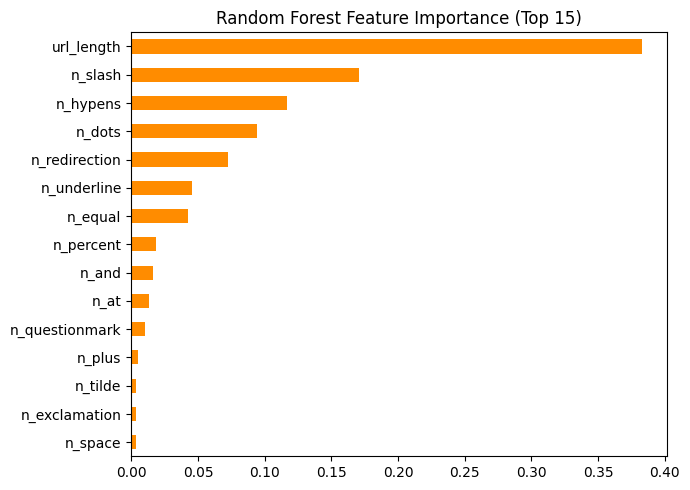

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(7,4))
plt.bar(res.Model, res.Accuracy, color="teal")
plt.title("Model Accuracy Comparison"); plt.ylabel("Accuracy")
plt.xticks(rotation=20); plt.ylim(0.5,1); plt.tight_layout()
plt.savefig("accuracy.png", dpi=200); plt.show()

best = res.sort_values("Accuracy", ascending=False).iloc[0].Model
ConfusionMatrixDisplay.from_predictions(y_test, preds[best], cmap="Blues")
plt.title(f"Confusion Matrix - {best}")
plt.savefig("confusion.png", dpi=200); plt.show()

rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).nlargest(15)
plt.figure(figsize=(7,5)); imp[::-1].plot.barh(color="darkorange")
plt.title("Random Forest Feature Importance (Top 15)")
plt.tight_layout(); plt.savefig("importance.png", dpi=200); plt.show()

In [ ]:
import joblib
joblib.dump(models[best], "model.pkl")
joblib.dump(list(X.columns), "features.pkl")
for f in ["model.pkl","features.pkl","accuracy.png","confusion.png","importance.png","results.csv"]:
    files.download(f)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

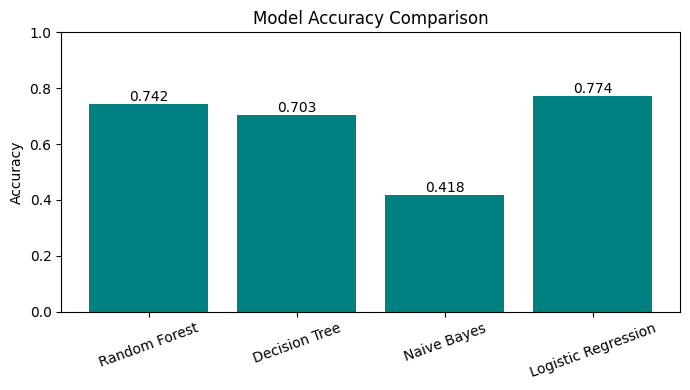

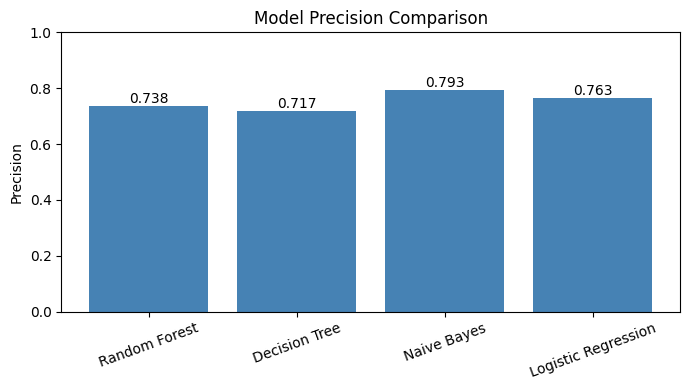

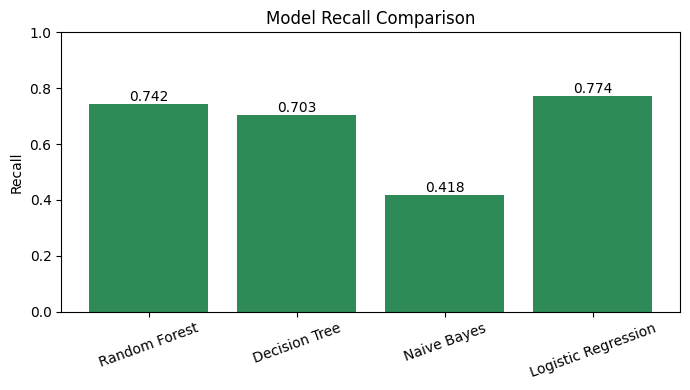

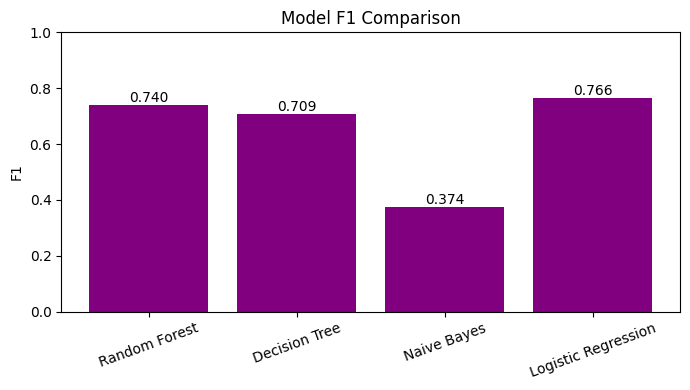

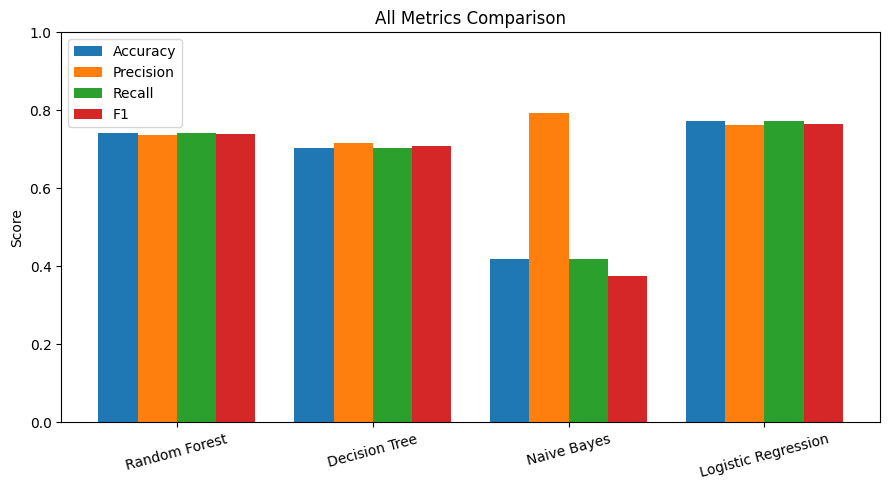

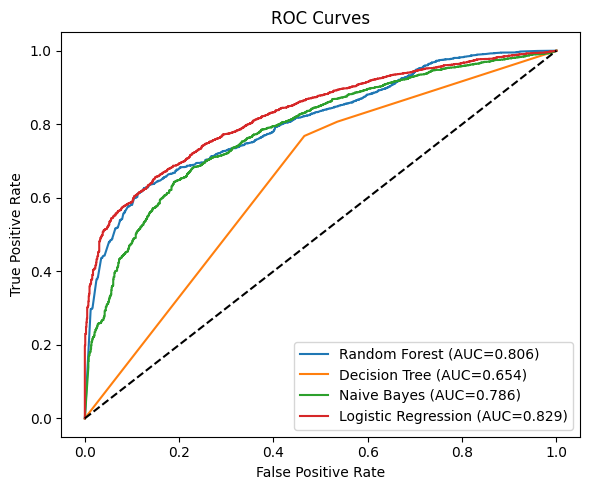

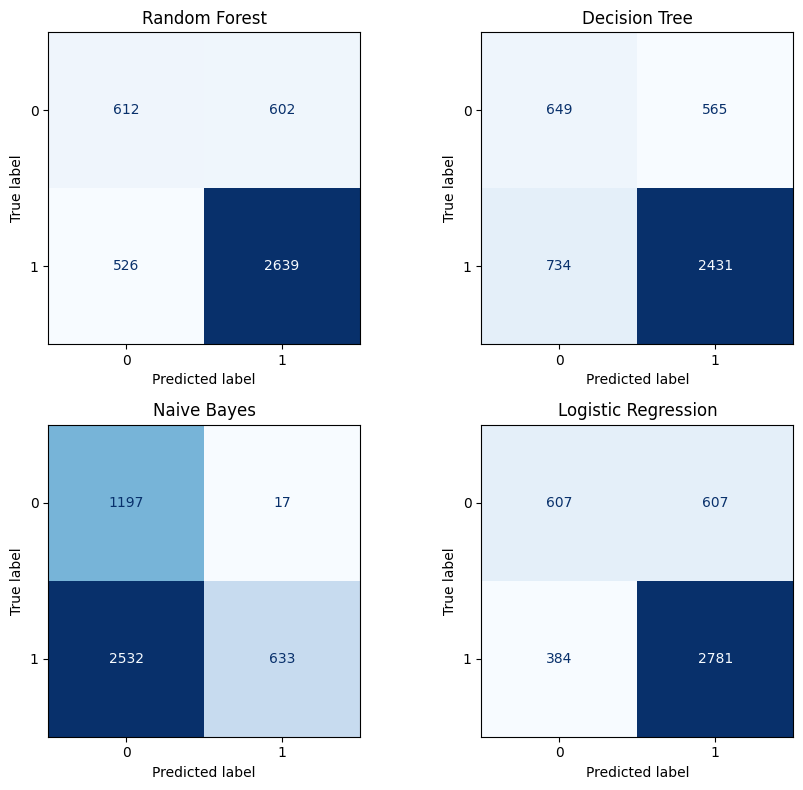

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (4 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, auc
from google.colab import files

# One bar chart per metric (replaces the old accuracy.png, Naive Bayes now visible)
colors = {"Accuracy":"teal","Precision":"steelblue","Recall":"seagreen","F1":"purple"}
for metric, fname in [("Accuracy","accuracy.png"),("Precision","precision.png"),
                      ("Recall","recall.png"),("F1","f1.png")]:
    plt.figure(figsize=(7,4))
    bars = plt.bar(res.Model, res[metric], color=colors[metric])
    plt.bar_label(bars, fmt="%.3f")
    plt.title(f"Model {metric} Comparison"); plt.ylabel(metric)
    plt.xticks(rotation=20); plt.ylim(0,1); plt.tight_layout()
    plt.savefig(fname, dpi=200); plt.show()

# All four metrics in one grouped chart
metrics = ["Accuracy","Precision","Recall","F1"]
x = np.arange(len(res)); w = 0.2
plt.figure(figsize=(9,5))
for i, m in enumerate(metrics):
    plt.bar(x + i*w, res[m], w, label=m)
plt.xticks(x + 1.5*w, res.Model, rotation=15)
plt.ylim(0,1); plt.ylabel("Score"); plt.title("All Metrics Comparison")
plt.legend(); plt.tight_layout()
plt.savefig("all_metrics.png", dpi=200); plt.show()

# ROC curves for all models
plt.figure(figsize=(6,5))
for n, m in models.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:,1])
    plt.plot(fpr, tpr, label=f"{n} (AUC={auc(fpr,tpr):.3f})")
plt.plot([0,1],[0,1],"k--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves"); plt.legend(loc="lower right"); plt.tight_layout()
plt.savefig("roc.png", dpi=200); plt.show()

# Confusion matrices for all 4 models
fig, axes = plt.subplots(2, 2, figsize=(9,8))
for ax, (n, p) in zip(axes.ravel(), preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, p, cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(n)
plt.tight_layout(); plt.savefig("confusion_all.png", dpi=200); plt.show()

# Download the new images
for f in ["accuracy.png","precision.png","recall.png","f1.png",
          "all_metrics.png","roc.png","confusion_all.png"]:
    files.download(f)

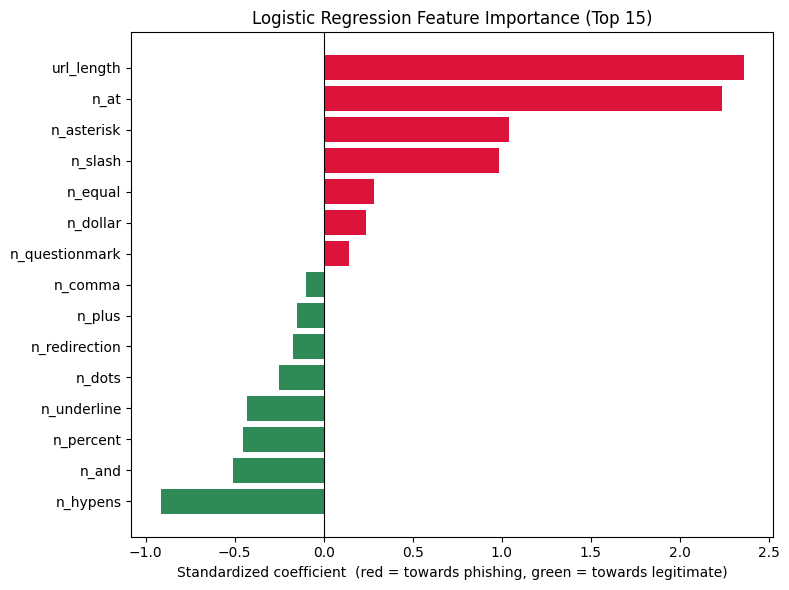

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import files

lr = models["Logistic Regression"]
coef = pd.Series(lr.coef_[0] * X_train.std().values, index=X.columns)
top = coef.reindex(coef.abs().nlargest(15).index).sort_values()

plt.figure(figsize=(8,6))
colors = ["seagreen" if v < 0 else "crimson" for v in top]
plt.barh(top.index, top.values, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic Regression Feature Importance (Top 15)")
plt.xlabel("Standardized coefficient  (red = towards phishing, green = towards legitimate)")
plt.tight_layout()
plt.savefig("lr_importance.png", dpi=200); plt.show()
files.download("lr_importance.png")